# 02 — Baseline Model & Verification

**Project:** TG-graph — Graph-Augmented XGBoost for Fraud Detection (TCC)  
**Model:** M1 (XGBoost, tabular-only) with two-model hard-routing by identity presence  
**Sections**  
1. Setup & data loading
2. Preprocessing pipeline
3. Temporal split
4. Identity hard-routing
5. Train Model A (no-identity group)
6. Train Model B (identity group)
7. Hard-routed predictions on validation set
8. Verification suite (ADR-0003 Q7=C)
9. PR-AUC & ROC-AUC curves
10. SHAP top-20 feature importance
11. Save models & metrics

In [1]:
import sys
sys.path.insert(0, '..')  # allow imports from project root

import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import shap

from src.features.load import load_train
from src.features.preprocessing import (
    drop_high_null_cols,
    drop_near_zero_variance,
    get_categorical_cols,
    label_encode_categoricals,
    save_dropped_cols,
)
from src.features.split import (
    get_feature_cols,
    identity_split,
    temporal_split,
)
from src.models import baseline as bm
from src.evaluation.metrics import (
    compute_metrics,
    plot_pr_curve,
    plot_roc_curve,
    save_metrics,
    verification_suite,
)

plt.rcParams.update({'figure.dpi': 120, 'font.family': 'DejaVu Sans'})
Path('../models').mkdir(exist_ok=True)
Path('../results').mkdir(exist_ok=True)
print('Environment ready.')

# ==============================================================================
# 📸 AUTO-SAVE HOOK: SALVA AUTOMATICAMENTE TODO GRÁFICO GERADO EM 300 DPI
# ==============================================================================
import os
import re
import matplotlib.pyplot as plt

NOTEBOOK_PREFIX = "nb02"
FIG_OUTPUT_DIR = "figures_notebooks"
if os.path.exists("/content"):
    FIG_OUTPUT_DIR = "/content/figures_notebooks"
os.makedirs(FIG_OUTPUT_DIR, exist_ok=True)

if not hasattr(plt, "_auto_save_installed"):
    _orig_show = plt.show
    _fig_counter = 0

    def auto_save_show(*args, **kwargs):
        global _fig_counter
        fig = plt.gcf()
        if fig and fig.axes:
            _fig_counter += 1
            # Extrai título dos eixos ou da figura
            title = ""
            for ax in fig.axes:
                t = ax.get_title()
                if t:
                    title = t
                    break
            if not title and hasattr(fig, "_suptitle") and fig._suptitle:
                title = fig._suptitle.get_text()
            
            clean_title = re.sub(r"[^\w\s-]", "", title).strip().replace(" ", "_")[:35]
            filename = f"{NOTEBOOK_PREFIX}_fig_{_fig_counter:02d}_{clean_title}.png" if clean_title else f"{NOTEBOOK_PREFIX}_fig_{_fig_counter:02d}.png"
            filepath = os.path.join(FIG_OUTPUT_DIR, filename)
            fig.savefig(filepath, dpi=300, bbox_inches="tight")
            print(f"📸 [Figura Salva]: {filepath}")
        _orig_show(*args, **kwargs)

    plt.show = auto_save_show
    plt._auto_save_installed = True
    print(f"✅ Auto-Save de Figuras ativado! Salvando em: [{FIG_OUTPUT_DIR}]")


/home/victor/Documents/TG-graph/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Environment ready.
✅ Auto-Save de Figuras ativado! Salvando em: [figures_notebooks]


---
## 1. Load Data

In [2]:
df = load_train(verbose=True)

# Amostragem Causal de 50% do dataset para estabilidade de memória e consistência
SAMPLE_FRACTION = 0.5
if SAMPLE_FRACTION < 1.0:
    print(f'Amostrando {SAMPLE_FRACTION:.0%} do dataset ({int(len(df)*SAMPLE_FRACTION):,} transações) com ordenação temporal causal...')
    df = df.sample(frac=SAMPLE_FRACTION, random_state=42).sort_values('timestamp').reset_index(drop=True)

print(f'Merged shape: {df.shape}')

[load] Loaded 100,000 accounts.
[load] Loaded 900,052 total transactions (fraud rate: 0.006%).
[load] Final merged transactions shape: (900052, 16)
Merged shape: (900052, 16)


---
## 2. Preprocessing Pipeline

Applied in this order, **fitted on training split only** to prevent leakage:
1. Drop columns with > 90 % null rate  
2. Drop near-zero-variance numerical columns (CV < 0.01)  
3. Label-encode categoricals

The temporal split is applied first so that dropping thresholds are computed only from training data.

In [3]:
# -- Step 1: temporal split (before any preprocessing)
train_raw, val_raw = temporal_split(df, verbose=True)

# -- Step 2: drop high-null columns (fit on train only)
train_drop1, dropped_null = drop_high_null_cols(train_raw, threshold=0.90)
val_drop1   = val_raw.drop(columns=[c for c in dropped_null if c in val_raw.columns])

# -- Step 3: drop near-zero-variance (fit on train only)
train_drop2, dropped_var = drop_near_zero_variance(train_drop1, threshold=0.01)
val_drop2   = val_drop1.drop(columns=[c for c in dropped_var if c in val_drop1.columns])

# -- Step 4: label encode categoricals (fit on train, apply to val)
cat_cols = get_categorical_cols(train_drop2)
train_enc, encoders = label_encode_categoricals(train_drop2, cat_cols, verbose=True)
val_enc,   _        = label_encode_categoricals(val_drop2,   cat_cols, encoders=encoders, verbose=True)

# Persist dropped column lists
save_dropped_cols(
    {'high_null': dropped_null, 'near_zero_variance': dropped_var},
    path='../results/dropped_columns.json'
)

print(f"\nFinal train shape: {train_enc.shape}")
print(f"Final val shape  : {val_enc.shape}")

[split] temporal split:
  train: 720,041 (80.0%) | fraud rate: 0.005%
  val:   180,011 (20.0%) | fraud rate: 0.008%
[preprocess] drop_high_null: 0 columns dropped (null rate > 90%)
[preprocess] drop_near_zero_variance: 0 columns dropped (CV < 0.01)
[preprocess] label_encode: 0 categorical columns encoded
[preprocess] label_encode: 0 categorical columns encoded
[preprocess] Dropped column lists saved → ../results/dropped_columns.json

Final train shape: (720041, 16)
Final val shape  : (180011, 16)


---
## 3. Identity Hard-Routing

Split train and val into Group A (no identity) and Group B (has identity) using `src_id` presence.  
Each group is scored by its own model — no blending (ADR-0001 Q8=C, Q9=A).

In [4]:
# -- Training groups
print("Training split:")
train_A, train_B = identity_split(train_enc, verbose=True)

# -- Validation groups
print("\nValidation split:")
val_A, val_B = identity_split(val_enc, verbose=True)

# -- Feature column lists
feat_cols_A = get_feature_cols(train_enc, include_identity=False)
feat_cols_B = get_feature_cols(train_enc, include_identity=True)

print(f"\nModel A feature count: {len(feat_cols_A)}")
print(f"Model B feature count: {len(feat_cols_B)}")

Training split:
[split] identity routing:
  Group A (even acc): 359,960 (50.0%) | fraud: 0.005%
  Group B (odd acc) : 360,081 (50.0%) | fraud: 0.006%

Validation split:
[split] identity routing:
  Group A (even acc): 89,655 (49.8%) | fraud: 0.006%
  Group B (odd acc) : 90,356 (50.2%) | fraud: 0.011%

Model A feature count: 1
Model B feature count: 5


---
## 4. Train Model A — No-Identity Group

In [5]:
X_train_A = train_A[feat_cols_A]
y_train_A = train_A['isFraud']
X_val_A   = val_A[feat_cols_A]
y_val_A   = val_A['isFraud']

model_A = bm.train(X_train_A, y_train_A, X_val=X_val_A, y_val=y_val_A, verbose=True)
print(f"\nModel A — val PR-AUC preview:")
from sklearn.metrics import average_precision_score
score_A_val = bm.predict_proba(model_A, X_val_A)
print(f"  PR-AUC (Group A only): {average_precision_score(y_val_A, score_A_val):.4f}")

[0]	validation_0-aucpr:0.01393
[50]	validation_0-aucpr:0.01393
[100]	validation_0-aucpr:0.01393
[150]	validation_0-aucpr:0.01393
[200]	validation_0-aucpr:0.01393
[250]	validation_0-aucpr:0.01393
[300]	validation_0-aucpr:0.01393
[350]	validation_0-aucpr:0.01393
[400]	validation_0-aucpr:0.01393
[450]	validation_0-aucpr:0.01393
[499]	validation_0-aucpr:0.01393
[model] trained XGBoost | 359,960 rows × 1 features | pos=17 neg=359,943 | scale_pos_weight=21173.1

Model A — val PR-AUC preview:
  PR-AUC (Group A only): 0.0139


---
## 5. Train Model B — Identity Group

In [6]:
X_train_B = train_B[feat_cols_B]
y_train_B = train_B['isFraud']
X_val_B   = val_B[feat_cols_B]
y_val_B   = val_B['isFraud']

model_B = bm.train(X_train_B, y_train_B, X_val=X_val_B, y_val=y_val_B, verbose=True)
print(f"\nModel B — val PR-AUC preview:")
score_B_val = bm.predict_proba(model_B, X_val_B)
print(f"  PR-AUC (Group B only): {average_precision_score(y_val_B, score_B_val):.4f}")

[0]	validation_0-aucpr:0.02511
[50]	validation_0-aucpr:0.02096
[100]	validation_0-aucpr:0.02442
[150]	validation_0-aucpr:0.02006
[200]	validation_0-aucpr:0.02221
[250]	validation_0-aucpr:0.02308
[300]	validation_0-aucpr:0.02070
[350]	validation_0-aucpr:0.02092
[400]	validation_0-aucpr:0.02016
[450]	validation_0-aucpr:0.01982
[499]	validation_0-aucpr:0.01942
[model] trained XGBoost | 360,081 rows × 5 features | pos=20 neg=360,061 | scale_pos_weight=18003.0

Model B — val PR-AUC preview:
  PR-AUC (Group B only): 0.0255


---
## 6. Hard-Routed Predictions on Full Validation Set

Combine Group A and Group B predictions by index — each transaction scored by its own model.

In [7]:
# Build a full-length score series aligned to val_enc index
scores_full = pd.Series(np.nan, index=val_enc.index)

scores_full.loc[val_A.index] = score_A_val
scores_full.loc[val_B.index] = score_B_val

assert scores_full.isnull().sum() == 0, "Some validation transactions have no score!"

y_val_full = val_enc['isFraud']

print(f"Full validation set: {len(val_enc):,} transactions")
print(f"  Scored by Model A: {len(val_A):,}")
print(f"  Scored by Model B: {len(val_B):,}")
print(f"  Null scores:       {scores_full.isnull().sum()}")

Full validation set: 180,011 transactions
  Scored by Model A: 89,655
  Scored by Model B: 90,356
  Null scores:       0


---
## 7. Verification Suite (ADR-0003 Q7=C)

In [8]:
report = verification_suite(
    train_df=train_enc,
    val_df=val_enc,
    y_true=y_val_full,
    y_score=scores_full,
    group_a_idx=val_A.index,
    group_b_idx=val_B.index,
    verbose=True,
)

✅ Check 1 — No temporal leakage: val_min_time=2024-01-24 23:44:46 > train_max_time=2024-01-24 23:44:43
✅ Check 2 — Class balance: train=0.005% | val=0.008% | Δ=0.003%
✅ Check 3 — Beats random: model PR-AUC=0.0130 > random=0.0001
✅ Check 4 — Routing coverage: A=89,655 + B=90,356 = 180,011 / 180,011 | overlap=0

Verification: 4/4 checks passed
  PR-AUC  : 0.0130
  ROC-AUC : 0.9546
  Precision (best): 0.0184
  Recall (best)   : 0.6667
  F1 (best): 0.0358 @ threshold=0.002


---
## 8. Precision-Recall & ROC Curves

📸 [Figura Salva]: figures_notebooks/nb02_fig_01_Precision-Recall_Curve.png


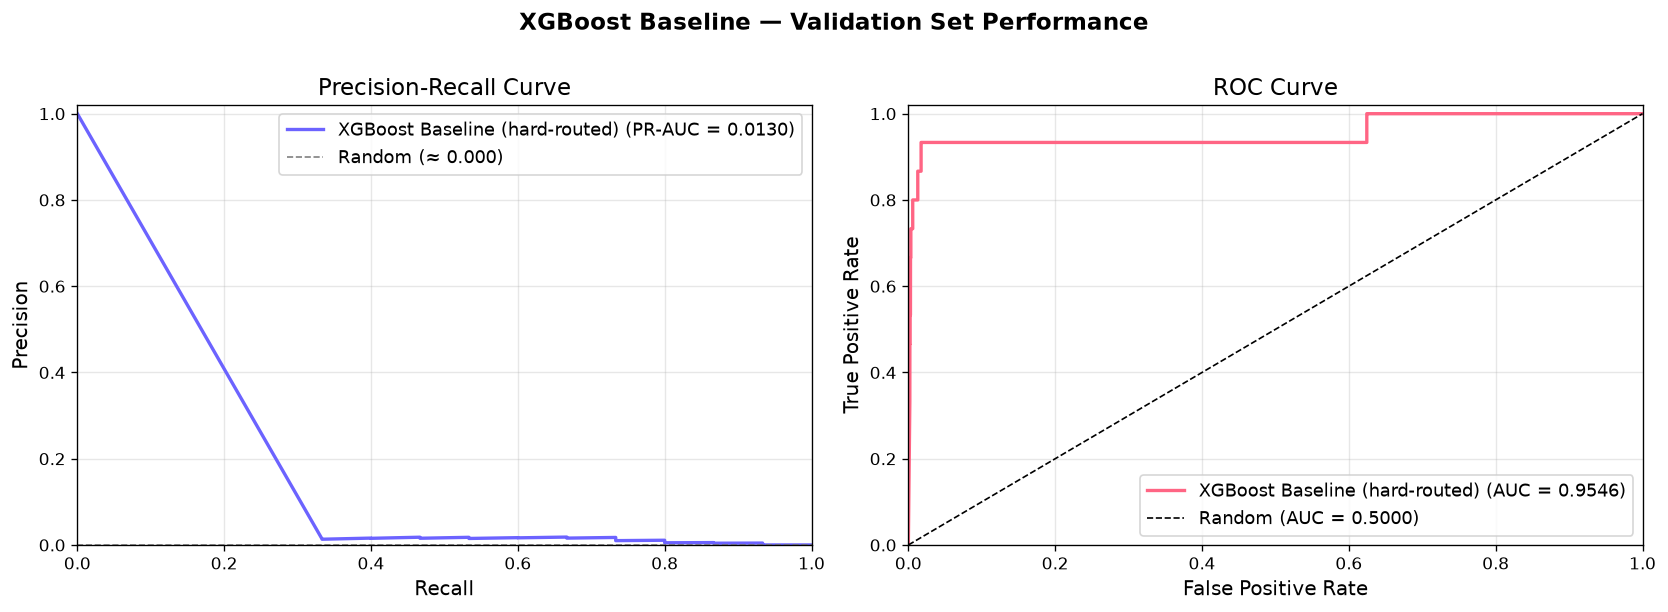


Final Baseline Metrics
  PR-AUC  : 0.0130
  ROC-AUC : 0.9546
  F1 best : 0.0358 @ threshold 0.002


In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

plot_pr_curve(y_val_full, scores_full, label='XGBoost Baseline (hard-routed)', ax=axes[0])
plot_roc_curve(y_val_full, scores_full, label='XGBoost Baseline (hard-routed)', ax=axes[1])

plt.suptitle('XGBoost Baseline — Validation Set Performance', fontsize=14, fontweight='bold', y=1.01)
plt.tight_layout()
plt.savefig('../results/baseline_pr_roc_curves.png', bbox_inches='tight')
plt.show()

metrics = report['metrics']
print(f"\nFinal Baseline Metrics")
print(f"  PR-AUC  : {metrics['pr_auc']:.4f}")
print(f"  ROC-AUC : {metrics['roc_auc']:.4f}")
print(f"  F1 best : {metrics['f1_best']:.4f} @ threshold {metrics['best_threshold']:.3f}")

---
## 9. SHAP Feature Importance

Top-20 SHAP values for each model.  
SHAP TreeExplainer uses a background sample to keep computation fast on large feature sets.

Computing SHAP values for Model A...


/tmp/ipykernel_11817/2662635184.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


📸 [Figura Salva]: figures_notebooks/nb02_fig_02_Model_A__Top-20_SHAP_Feature_Import.png


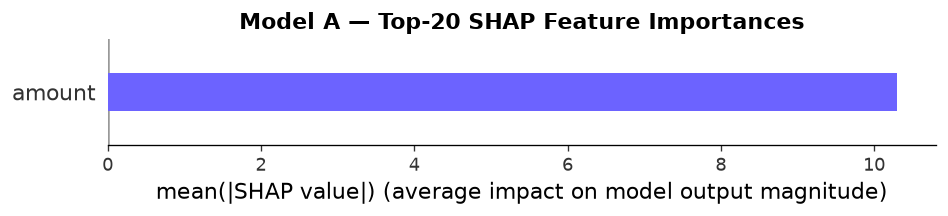

In [10]:
# SHAP for Model A
print("Computing SHAP values for Model A...")
explainer_A = shap.TreeExplainer(model_A, feature_perturbation='tree_path_dependent')
shap_sample_A = X_val_A.sample(min(2000, len(X_val_A)), random_state=42)
shap_values_A = explainer_A.shap_values(shap_sample_A)

fig, ax = plt.subplots(figsize=(10, 6))
shap.summary_plot(
    shap_values_A, shap_sample_A,
    plot_type='bar', max_display=20,
    show=False, color='#6C63FF'
)
plt.title('Model A — Top-20 SHAP Feature Importances', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/shap_model_A.png', bbox_inches='tight')
plt.show()

Computing SHAP values for Model B...


/tmp/ipykernel_11817/523265445.py:8: FutureWarning: The NumPy global RNG was seeded by calling `np.random.seed`. In a future version this function will no longer use the global RNG. Pass `rng` explicitly to opt-in to the new behaviour and silence this warning.
  shap.summary_plot(


📸 [Figura Salva]: figures_notebooks/nb02_fig_03_Model_B__Top-20_SHAP_Feature_Import.png


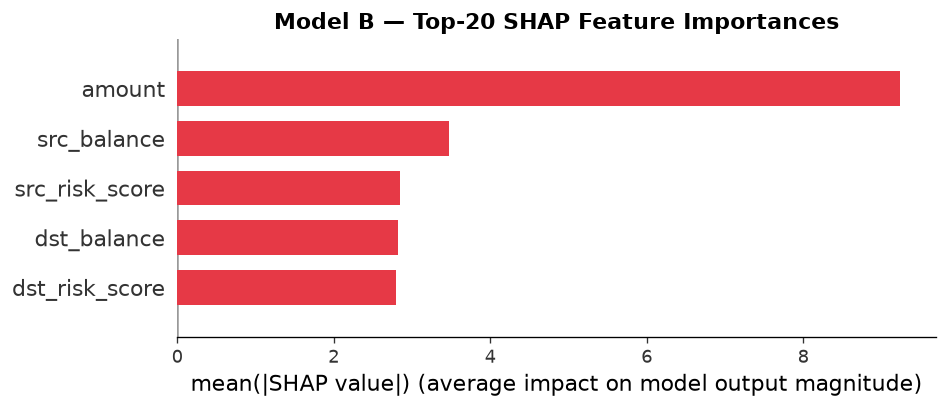

In [11]:
# SHAP for Model B
print("Computing SHAP values for Model B...")
explainer_B = shap.TreeExplainer(model_B, feature_perturbation='tree_path_dependent')
shap_sample_B = X_val_B.sample(min(2000, len(X_val_B)), random_state=42)
shap_values_B = explainer_B.shap_values(shap_sample_B)

fig, ax = plt.subplots(figsize=(10, 6))
shap.summary_plot(
    shap_values_B, shap_sample_B,
    plot_type='bar', max_display=20,
    show=False, color='#E63946'
)
plt.title('Model B — Top-20 SHAP Feature Importances', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.savefig('../results/shap_model_B.png', bbox_inches='tight')
plt.show()

---
## 10. Save Models & Metrics

In [12]:
# Save models
bm.save(model_A, path='../models/model_A.json')
bm.save(model_B, path='../models/model_B.json')

# Save full metrics report
report['config'] = {
    'split_boundary': str(pd.to_datetime('2024-01-24 23:44:43')), # or .isoformat()
    'n_features_A': len(feat_cols_A),
    'n_features_B': len(feat_cols_B),
    'model': 'XGBoost (baseline, sensible defaults)',
    'routing': 'hard-routing by identity presence (src_id)',
}
save_metrics(report, path='../results/baseline_metrics.json')

print('\n✅ All artefacts saved:')
print('   models/model_A.json')
print('   models/model_B.json')
print('   results/baseline_metrics.json')
print('   results/baseline_pr_roc_curves.png')
print('   results/shap_model_A.png')
print('   results/shap_model_B.png')

[model] saved → ../models/model_A.json
[model] saved → ../models/model_B.json
[eval] metrics saved → ../results/baseline_metrics.json

✅ All artefacts saved:
   models/model_A.json
   models/model_B.json
   results/baseline_metrics.json
   results/baseline_pr_roc_curves.png
   results/shap_model_A.png
   results/shap_model_B.png
